# ECO346 Quiz 2 (Section A): your personal notebook

<a href="https://colab.research.google.com/github/rafi-amiruddin/DVTE/blob/main/data/quiz2/quiz2_sectionA.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**What to do (in Google Colab, signed in with your CUI account)**

1. In the next cell, replace `FA24-BED-000` with **your own** registration number.
2. From the menu choose **Runtime → Run all**. If Colab warns that the notebook was not authored by Google, click **Run anyway**.
3. Read your results and answer the Google Form.

Change nothing else. If you change something by mistake, choose **Runtime → Restart session and run all**.
Every student gets different data, so your answers are yours alone. You do not need to save this notebook.

In [1]:
REG = "FA24-BED-034"      # <-- change ONLY this line, e.g. "FA24-BED-047"

## 0. Setting up (just run it)

This cell loads your 3,000 persons from the course data file and works out your personal numbers.

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

try:
    plt.style.use("https://raw.githubusercontent.com/rafi-amiruddin/DVTE/main/style/dvte.mplstyle")
except Exception:
    pass
plt.rcParams.update({"figure.figsize": (9, 3.6), "font.size": 10})

REG = REG.strip().upper()
if not re.fullmatch(r"FA24-BED-\d{3}", REG):
    raise ValueError("Write your registration number exactly like FA24-BED-047, then run again.")

URL = "https://raw.githubusercontent.com/rafi-amiruddin/DVTE/main/data/quiz2/quiz2_data.csv"
data = pd.read_csv(URL)
me = data[data["reg"] == REG].reset_index(drop=True)
if me.empty:
    raise ValueError(f"{REG} is not in the quiz file. Check the number, or tell the instructor.")

n = int(REG[-3:])
b = n % 11 + 1              # histogram bin width (years)
h = (n // 2) % 10 + 1       # density bandwidth (years)
f = n % 7 + 1               # your figure for Q11-Q13
rng = np.random.default_rng(n)   # fixes the order of the versions shown to you

age = me["age"].to_numpy(float)
earn = me.loc[me["earn_annual"] > 0, "earn_annual"].to_numpy(float)

print(f"Registration number : {REG}")
print(f"Persons in your data: {len(me):,}   (earners: {len(earn):,})")
print(f"Your bin width b    : {b} years")
print(f"Your bandwidth h    : {h} years")
print(f"Your figure f       : Figure {f}")

Registration number : FA24-BED-034
Persons in your data: 3,000   (earners: 623)
Your bin width b    : 2 years
Your bandwidth h    : 8 years
Your figure f       : Figure 7


## 1. Histogram of age (for Q1)

Below are **two versions** of the histogram of age in your data, both with bins of width *b* years starting at 0.
They differ in only one thing: what happens to a person whose age falls **exactly on the edge** between two bins.
Read the code line printed for each version.

Version A:  pd.cut(age, edges, right=True, include_lowest=True)
           tallest bar: 199 persons, bin starting at age 0

Version B:  pd.cut(age, edges, right=False)
           tallest bar: 199 persons, bin starting at age 4



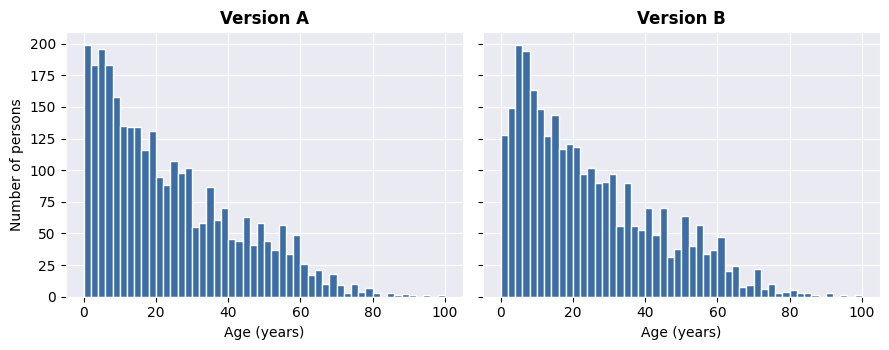

In [3]:
edges = np.arange(0, age.max() + b + 1, b)
versions = {
    "pd.cut(age, edges, right=False)": pd.cut(age, edges, right=False),
    "pd.cut(age, edges, right=True, include_lowest=True)": pd.cut(age, edges, right=True, include_lowest=True),
}
order = list(versions)
rng.shuffle(order)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, letter, call in zip(axes, "AB", order):
    counts = pd.Series(versions[call]).value_counts(sort=False).to_numpy()
    k = counts.argmax()
    ax.bar(edges[:-1], counts, width=b, align="edge", color="#3B6EA8", edgecolor="white")
    ax.set(title=f"Version {letter}", xlabel="Age (years)")
    print(f"Version {letter}:  {call}")
    print(f"           tallest bar: {counts[k]} persons, bin starting at age {edges[k]:g}\n")
axes[0].set_ylabel("Number of persons")
plt.tight_layout(); plt.show()

## 2. Density of age (for Q2)

Below are **three versions** of a Gaussian kernel density of age in your data.
Only one of them uses a bandwidth of exactly **h years**. Read the code line printed for each version,
and remember what `bw_method` measures in `scipy`'s `gaussian_kde`.

Version A:  gaussian_kde(age, bw_method = h / age.std())
           curve is highest at age 11.2

Version B:  gaussian_kde(age)
           curve is highest at age 7.1

Version C:  gaussian_kde(age, bw_method = h)
           curve is highest at age 24.1



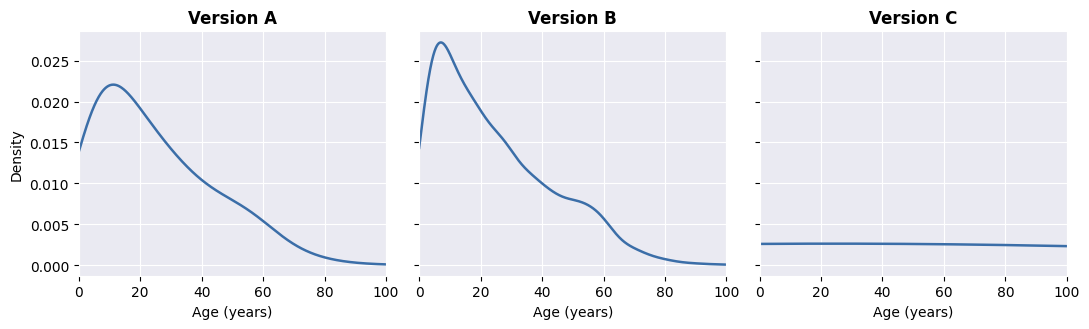

In [4]:
grid = np.round(np.arange(0, 100.0001, 0.1), 1)
sd = age.std(ddof=1)
calls = {
    "gaussian_kde(age, bw_method = h / age.std())": h / sd,
    "gaussian_kde(age)": "scott",
    "gaussian_kde(age, bw_method = h)": h,
}
order = list(calls)
rng.shuffle(order)

fig, axes = plt.subplots(1, 3, sharey=True, figsize=(11, 3.4))
for ax, letter, call in zip(axes, "ABC", order):
    dens = gaussian_kde(age, bw_method=calls[call])(grid)
    ax.plot(grid, dens, color="#3B6EA8", lw=1.8)
    ax.set(title=f"Version {letter}", xlabel="Age (years)", xlim=(0, 100))
    print(f"Version {letter}:  {call}")
    print(f"           curve is highest at age {grid[dens.argmax()]:.1f}\n")
axes[0].set_ylabel("Density")
plt.tight_layout(); plt.show()

## 3. Inequality of earnings (for Q3 and Q4)

Your earners are the persons in your data with annual earnings above zero.
The Lorenz curve and the table show what share of all their earnings goes to the poorest 10%, 20%, ... of them.

Poorest share of earners,Their share of all earnings (%)
10%,1.3
20%,4.5
30%,9.3
40%,15.1
50%,22.1
60%,30.1
70%,39.3
80%,50.8
90%,66.8
100%,100.0


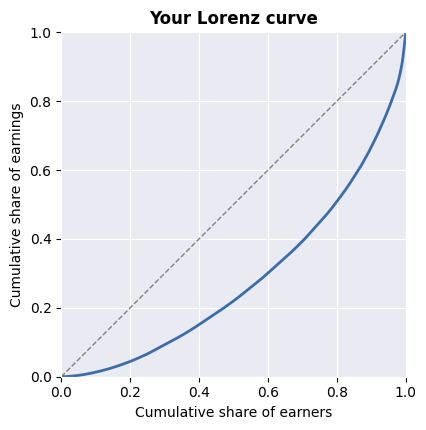

In [5]:
e = np.sort(earn)
total = e.sum()
p = np.arange(0.1, 1.01, 0.1)
L = [e[: int(round(q * len(e)))].sum() / total for q in p]

table = pd.DataFrame({
    "Poorest share of earners": [f"{q:.0%}" for q in p],
    "Their share of all earnings (%)": [f"{100 * x:.1f}" for x in L],
})
try:
    display(table.style.hide(axis="index"))
except Exception:                      # older pandas
    print(table.to_string(index=False))

cum = np.concatenate([[0], np.cumsum(e) / total])
pop = np.linspace(0, 1, len(cum))
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
ax.plot(pop, cum, color="#3B6EA8", lw=2)
ax.set(xlabel="Cumulative share of earners", ylabel="Cumulative share of earnings",
       xlim=(0, 1), ylim=(0, 1), aspect="equal", title="Your Lorenz curve")
plt.tight_layout(); plt.show()

## 4. Your figure (for Q11, Q12 and Q13)

The cell below draws **your** figure, number *f*, exactly as it was "published", from your own data.
Under it is the **claim** that the author made. The claim is wrong or unsupported because of how the figure was drawn.

Right after it, the notebook draws a **corrected** version of the same figure, without a title.
Use the first figure to answer Q11 and the corrected one for the numbers in Q12 and Q13.

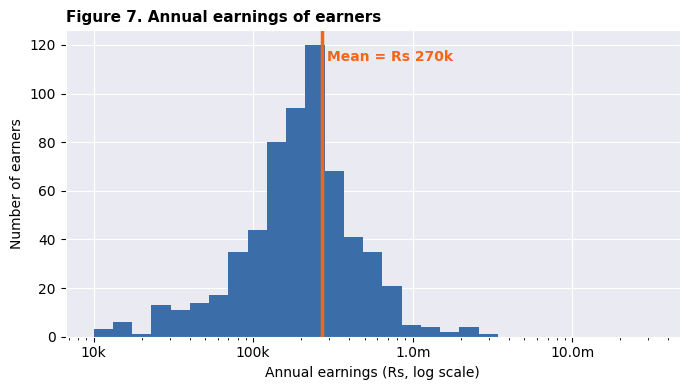

CLAIM (Figure 7): The typical earner earns about Rs 270k a year, as the mean line shows.


In [6]:
from matplotlib.ticker import FuncFormatter
rs = FuncFormatter(lambda v, _: f"{v/1e6:.1f}m" if v >= 1e6 else f"{v/1e3:.0f}k")
BLUE, ORANGE, GREEN = "#3B6EA8", "#F36619", "#2E7D32"
logbins = np.logspace(4, 7.5, 30)
grid = np.round(np.arange(0, 100.0001, 0.1), 1)
r2 = np.random.default_rng(1000 + n)

def gkde(x, bw, g):
    z = (g[:, None] - x[None, :]) / bw
    return np.exp(-0.5 * z**2).sum(1) / (len(x) * bw * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(7, 4))
if f == 1:
    g = np.linspace(-25, 100, 1251)
    d = gkde(age, 5, g)
    m = (g >= 0) & (g <= 5)
    area = d[m].sum() * (g[1] - g[0])
    ax.plot(g, d, color=BLUE, lw=2); ax.fill_between(g[m], d[m], color=ORANGE, alpha=0.45)
    ax.set(xlabel="Age (years)", ylabel="Density")
    title = "Density of age"
    claim = f"The shaded area between ages 0 and 5 is about {area:.0%}, so about one person in ten is under five."
elif f == 2:
    ax.hist(earn, bins=40, color=BLUE); ax.xaxis.set_major_formatter(rs)
    ax.set(xlabel="Annual earnings (Rs)", ylabel="Number of earners")
    title = "Annual earnings of earners"
    claim = "Almost all earners earn about the same amount, so earnings inequality is negligible."
elif f == 3:
    for s, lab, col in [(1, "Men", BLUE), (2, "Women", ORANGE)]:
        ax.hist(me.loc[(me.earn_annual > 0) & (me.sex == s), "earn_annual"], bins=logbins, color=col, alpha=0.6, label=lab)
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(rs); ax.legend()
    ax.set(xlabel="Annual earnings (Rs, log scale)", ylabel="Number of earners")
    title = "Annual earnings of men and women earners"
    claim = "At every earnings level women are far behind men, so women's earnings distribution lies well below men's."
elif f == 4:
    ax.plot(grid, gkde(age, 12, grid), color=BLUE, lw=2); ax.set(xlabel="Age (years)", ylabel="Density", xlim=(0, 100))
    title = "Density of age"
    claim = "The curve is smooth, so ages were reported accurately, with no bunching at round numbers."
elif f == 5:
    e5 = r2.permutation(earn)
    c5 = np.concatenate([[0], np.cumsum(e5) / e5.sum()])
    ax.plot([0, 1], [0, 1], color="grey", lw=1, ls="--"); ax.plot(np.linspace(0, 1, len(c5)), c5, color=BLUE, lw=1.5)
    ax.set(xlabel="Cumulative share of earners", ylabel="Cumulative share of earnings", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    title = "Lorenz curve of annual earnings"
    claim = "The curve hugs the equality line, so the Gini is close to zero and earnings are almost equally shared."
elif f == 6:
    ax.hist(earn[earn <= 1e6], bins=40, color=BLUE); ax.set_xlim(0, 1e6); ax.xaxis.set_major_formatter(rs)
    ax.set(xlabel="Annual earnings (Rs)", ylabel="Number of earners")
    title = "Annual earnings of earners"
    claim = "No earner in the survey earns more than Rs 1 million a year."
else:
    mean_ = earn.mean()
    ax.hist(earn, bins=logbins, color=BLUE); ax.axvline(mean_, color=ORANGE, lw=2.5)
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(rs)
    ax.text(mean_ * 1.08, ax.get_ylim()[1] * 0.9, f"Mean = Rs {mean_/1e3:,.0f}k", color=ORANGE, fontweight="bold")
    ax.set(xlabel="Annual earnings (Rs, log scale)", ylabel="Number of earners")
    title = "Annual earnings of earners"
    claim = f"The typical earner earns about Rs {mean_/1e3:,.0f}k a year, as the mean line shows."

ax.set_title(f"Figure {f}. {title}", loc="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()
print(f"CLAIM (Figure {f}): {claim}")

**Corrected version of your figure** (no title; for Q12 and Q13)

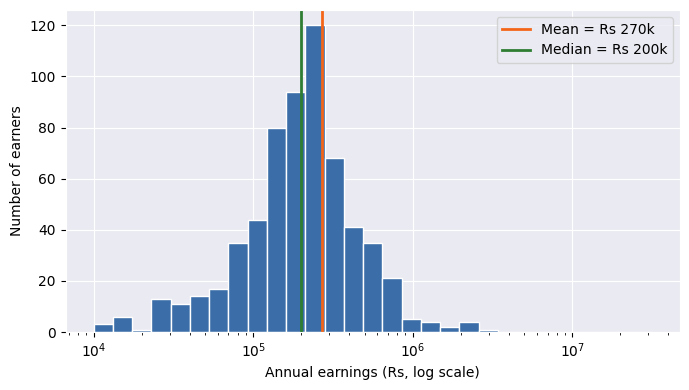

In [7]:
sd = age.std(ddof=1)
pop_ = np.linspace(0, 1, len(earn) + 1)
cum_ = np.concatenate([[0], np.cumsum(np.sort(earn)) / earn.sum()])
fig, ax = plt.subplots(figsize=(7, 4))
if f == 1:
    ax.hist(age, bins=np.arange(0, 105, 5), weights=np.full(len(age), 100 / len(age)), color=BLUE, edgecolor="white")
    ax.set(xlabel="Age (years)", ylabel="Percent of persons")
elif f in (2, 6):
    ax.hist(earn, bins=logbins, color=BLUE, edgecolor="white")
    ax.set_xscale("log"); ax.set(xlabel="Annual earnings (Rs, log scale)", ylabel="Number of earners")
elif f == 3:
    for s, lab, col in [(1, "Men", BLUE), (2, "Women", ORANGE)]:
        x = me.loc[(me.earn_annual > 0) & (me.sex == s), "earn_annual"]
        ax.hist(x, bins=logbins, weights=np.full(len(x), 100 / len(x)), alpha=0.6, color=col, label=f"{lab} (n = {len(x)})")
    ax.set_xscale("log"); ax.legend()
    ax.set(xlabel="Annual earnings (Rs, log scale)", ylabel="Percent of earners in each group")
elif f == 4:
    ax.plot(grid, gaussian_kde(age, bw_method=1 / sd)(grid), color=BLUE)
    ax.set(xlabel="Age (years)", ylabel="Density (bandwidth 1 year)", xlim=(0, 100))
elif f == 5:
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
    ax.plot(pop_, cum_, color=BLUE, lw=2)
    ax.set(xlabel="Cumulative share of earners (poorest first)", ylabel="Cumulative share of earnings", aspect="equal")
else:
    ax.hist(earn, bins=logbins, color=BLUE, edgecolor="white")
    for v, lab, col in [(np.mean(earn), "Mean", ORANGE), (np.median(earn), "Median", GREEN)]:
        ax.axvline(v, color=col, lw=2, label=f"{lab} = Rs {v/1e3:,.0f}k")
    ax.set_xscale("log"); ax.legend()
    ax.set(xlabel="Annual earnings (Rs, log scale)", ylabel="Number of earners")
plt.tight_layout(); plt.show()

---
You are done with the notebook. Go back to the Google Form and answer the questions.
Keep this notebook open until you have submitted the form.